# Homework 3 - NYC taxi demand dataset

In [1]:
import matplotlib.pyplot as plt
import polars as pl

DATA_DIR = "data"

MONEY_COLS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "airport_fee",
]
VENDOR_IDS = [1, 2, 6, 7]
RATECODE_IDS = [1, 2, 3, 4, 5, 6, 99]

BOROUGH = pl.Enum(
    [
        "bronx",
        "brooklyn",
        "ewr",
        "manhattan",
        "queens",
        "staten_island",
        "unknown",
        "outside_nyc",
    ]
)
PAYMENT_TYPE = pl.Enum(["card", "cash", "other"])

## 1. Data reading

In [2]:
def read_rides() -> pl.LazyFrame:
    months = [
        pl.scan_parquet(f"{DATA_DIR}/{month}.parquet").with_columns(
            pl.col("tpep_pickup_datetime", "tpep_dropoff_datetime").dt.cast_time_unit(
                "us"
            )
        )
        for month in range(1, 13)
    ]
    return (
        pl.concat(months)
        .rename({"Airport_fee": "airport_fee"})
        .filter(
            pl.col("tpep_pickup_datetime").dt.year() == 2024,
            pl.col("tpep_dropoff_datetime") <= pl.datetime(2025, 1, 1),
        )
        .with_columns(
            pl.col("VendorID", "RatecodeID", "passenger_count", "payment_type").cast(
                pl.UInt8
            ),
            pl.col("PULocationID", "DOLocationID").cast(pl.UInt16),
            pl.col("store_and_fwd_flag").cast(pl.Enum(["N", "Y"])),
        )
    )


def read_zones() -> pl.LazyFrame:
    return pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv").select(
        pl.col("LocationID").cast(pl.UInt16),
        pl.col("Borough")
        .replace("N/A", "outside_nyc")
        .str.to_lowercase()
        .str.replace(" ", "_")
        .cast(BOROUGH)
        .alias("borough"),
    )

In [3]:
read_rides().collect_schema()

Schema([('VendorID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='us', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='us', time_zone=None)),
        ('passenger_count', UInt8),
        ('trip_distance', Float64),
        ('RatecodeID', UInt8),
        ('store_and_fwd_flag', Enum(categories=['N', 'Y'])),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt8),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('airport_fee', Float64)])

In [4]:
read_zones().collect()

LocationID,borough
u16,enum
1,"""ewr"""
2,"""queens"""
3,"""bronx"""
4,"""manhattan"""
5,"""staten_island"""
…,…
261,"""manhattan"""
262,"""manhattan"""
263,"""manhattan"""


## 2. Data cleaning and filtering

In [5]:
def clean(rides: pl.LazyFrame) -> pl.LazyFrame:
    trip_duration = pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")
    return rides.with_columns(
        pl.col("passenger_count").fill_null(1).clip(upper_bound=6),
        pl.col(MONEY_COLS).fill_null(0).abs(),
    ).filter(
        pl.col("passenger_count") > 0,
        trip_duration <= pl.duration(hours=2),
        ~pl.any_horizontal(pl.col(MONEY_COLS) > 1000),
        pl.col("VendorID").is_in(VENDOR_IDS),
        pl.col("RatecodeID").is_in(RATECODE_IDS),
    )

In [6]:
rows_raw = read_rides().select(pl.len()).collect().item()
rows_clean = read_rides().pipe(clean).select(pl.len()).collect().item()

print(f"Rows before cleaning: {rows_raw}")
print(f"Rows after cleaning: {rows_clean} ({rows_clean / rows_raw:.2%})")

Rows before cleaning: 41169064
Rows after cleaning: 36635240 (88.99%)


## 3. Data transformation

In [7]:
def transform(rides: pl.LazyFrame, zones: pl.LazyFrame) -> pl.LazyFrame:
    pickup_time = pl.col("tpep_pickup_datetime").dt.time()
    is_rush_hour = (pl.col("tpep_pickup_datetime").dt.weekday() <= 5) & (
        pickup_time.is_between(pl.time(6, 30), pl.time(9, 30))
        | pickup_time.is_between(pl.time(15, 30), pl.time(20))
    )
    return (
        rides.join(
            zones.rename({"LocationID": "PULocationID", "borough": "pickup_borough"}),
            on="PULocationID",
            how="left",
        )
        .join(
            zones.rename({"LocationID": "DOLocationID", "borough": "dropoff_borough"}),
            on="DOLocationID",
            how="left",
        )
        .drop("PULocationID", "DOLocationID")
        .with_columns(
            pl.col("payment_type").replace_strict(
                {1: "card", 2: "cash"}, default="other", return_dtype=PAYMENT_TYPE
            ),
            (pl.col("airport_fee") > 0).alias("is_airport_ride"),
            is_rush_hour.alias("is_rush_hour"),
        )
    )

In [8]:
read_rides().pipe(clean).pipe(transform, read_zones()).head().collect()

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_borough,dropoff_borough,is_airport_ride,is_rush_hour
u8,datetime[μs],datetime[μs],u8,f64,u8,enum,enum,f64,f64,f64,f64,f64,f64,f64,f64,f64,enum,enum,bool,bool
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""","""cash""",17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0,"""manhattan""","""manhattan""",false,false
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""","""card""",10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0,"""manhattan""","""manhattan""",false,false
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""","""card""",23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0,"""manhattan""","""manhattan""",false,false
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.4,1,"""N""","""card""",10.0,3.5,0.5,2.0,0.0,1.0,17.0,2.5,0.0,"""manhattan""","""manhattan""",false,false
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.8,1,"""N""","""card""",7.9,3.5,0.5,3.2,0.0,1.0,16.1,2.5,0.0,"""manhattan""","""manhattan""",false,false


## 4. Feature extraction

In [9]:
def dummies(col: str, dtype: pl.Enum) -> list[pl.Expr]:
    return [
        (pl.col(col) == value).alias(f"{col}_{value}") for value in dtype.categories
    ]


def extract_features(rides: pl.LazyFrame) -> pl.LazyFrame:
    return (
        rides.with_columns(
            pl.col("tpep_pickup_datetime").dt.date().alias("date"),
            *dummies("payment_type", PAYMENT_TYPE),
            *dummies("pickup_borough", BOROUGH),
            *dummies("dropoff_borough", BOROUGH),
        )
        .group_by("date")
        .agg(
            pl.len().alias("n_rides"),
            pl.col("is_airport_ride").sum().alias("n_airport_rides"),
            pl.col("is_rush_hour").sum().alias("n_rush_hour_rides"),
            pl.col("^(payment_type|pickup_borough|dropoff_borough)_.*$")
            .sum()
            .name.prefix("n_"),
            pl.col("fare_amount").mean().alias("avg_fare_amount"),
            pl.col("trip_distance").median().alias("median_trip_distance"),
            pl.col("total_amount").sum().alias("total_amount_sum"),
            *[
                pl.col("total_amount")
                .filter(pl.col("payment_type") == payment)
                .sum()
                .alias(f"total_amount_{payment}")
                for payment in PAYMENT_TYPE.categories
            ],
            pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
            pl.col("passenger_count")
            .sum()
            .cast(pl.UInt32)
            .alias("passenger_count_sum"),
        )
        .with_columns(
            pl.col("date").dt.quarter().alias("quarter"),
            pl.col("date").dt.month().alias("month"),
            pl.col("date").dt.day().alias("day_of_month"),
            pl.col("date").dt.weekday().alias("day_of_week"),
            (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
        )
        .sort("date")
    )

In [10]:
dataset = (
    read_rides()
    .pipe(clean)
    .pipe(transform, read_zones())
    .pipe(extract_features)
    .collect()
)
dataset.write_parquet("dataset.parquet")

## 5. Data analysis

In [11]:
dataset.shape

(366, 36)

In [12]:
dataset.head()

date,n_rides,n_airport_rides,n_rush_hour_rides,n_payment_type_card,n_payment_type_cash,n_payment_type_other,n_pickup_borough_bronx,n_pickup_borough_brooklyn,n_pickup_borough_ewr,n_pickup_borough_manhattan,n_pickup_borough_queens,n_pickup_borough_staten_island,n_pickup_borough_unknown,n_pickup_borough_outside_nyc,n_dropoff_borough_bronx,n_dropoff_borough_brooklyn,n_dropoff_borough_ewr,n_dropoff_borough_manhattan,n_dropoff_borough_queens,n_dropoff_borough_staten_island,n_dropoff_borough_unknown,n_dropoff_borough_outside_nyc,avg_fare_amount,median_trip_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,congestion_surcharge_sum,passenger_count_sum,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,u32,i8,i8,i8,i8,bool
2024-01-01,69665,8352,19398,52970,14491,2204,82,664,21,59261,9270,3,271,93,583,3825,388,58606,5183,31,444,605,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,1,1,1,1,false
2024-01-02,72583,9828,31014,55174,15387,2022,167,684,20,60493,10897,2,266,54,555,3411,319,62613,4831,32,385,437,21.501448,1.82,2.2501e6,1.8023e6,396334.47,51441.03,160615.0,104071,1,1,2,2,false
2024-01-03,79566,9140,33389,61343,16202,2021,228,679,16,68074,10217,1,315,36,640,3464,282,69706,4589,14,473,398,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,1,1,3,3,false
2024-01-04,99077,8270,43572,78738,17994,2345,244,666,10,88459,9272,1,385,40,757,3463,226,89107,4615,14,549,346,18.866102,1.75,2.7604e6,2.2559e6,444631.77,59823.2,226627.5,135815,1,1,4,4,false
2024-01-05,98860,7460,40518,78701,17699,2460,183,606,8,89232,8399,1,394,37,651,3182,222,89459,4373,20,608,345,18.246814,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137166,1,1,5,5,false


In [13]:
dataset.describe()

statistic,date,n_rides,n_airport_rides,n_rush_hour_rides,n_payment_type_card,n_payment_type_cash,n_payment_type_other,n_pickup_borough_bronx,n_pickup_borough_brooklyn,n_pickup_borough_ewr,n_pickup_borough_manhattan,n_pickup_borough_queens,n_pickup_borough_staten_island,n_pickup_borough_unknown,n_pickup_borough_outside_nyc,n_dropoff_borough_bronx,n_dropoff_borough_brooklyn,n_dropoff_borough_ewr,n_dropoff_borough_manhattan,n_dropoff_borough_queens,n_dropoff_borough_staten_island,n_dropoff_borough_unknown,n_dropoff_borough_outside_nyc,avg_fare_amount,median_trip_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,congestion_surcharge_sum,passenger_count_sum,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100096.284153,8977.855191,29942.199454,82240.898907,14923.442623,2931.942623,206.071038,882.128415,15.983607,88509.997268,10106.715847,2.579235,312.625683,60.18306,590.032787,4008.661202,284.52459,89042.224044,5212.081967,25.251366,448.89071,484.617486,19.952296,1.718634,2.9111e6,2.4607e6,372228.863825,78155.394973,230203.751421,134959.76776,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15372.283484,1716.376375,19694.172232,14161.103695,1357.230224,554.311622,51.127939,201.839764,7.71263,15154.424625,1764.94245,1.735371,57.290409,18.122773,67.941264,581.872824,73.624208,14677.839829,689.257964,6.752549,92.05141,93.74735,1.204554,0.10091,461499.865082,428830.626989,36188.898027,17265.430834,37864.663724,18725.118942,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",47390.0,3355.0,0.0,34052.0,10244.0,1656.0,48.0,298.0,2.0,41757.0,4935.0,0.0,149.0,23.0,370.0,1831.0,122.0,41657.0,2826.0,9.0,192.0,261.0,16.676264,1.5,1.3260e6,996577.34,240633.43,41303.84,107825.0,74198.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",89572.0,7869.0,0.0,72543.0,14109.0,2566.0,166.0,731.0,10.0,77349.0,8862.0,1.0,273.0,46.0,544.0,3682.0,236.0,78535.0,4773.0,20.0,390.0,418.0,19.125929,1.66,2.5818e6,2.1701e6,352429.45,65781.9,203501.0,122219.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",100781.0,9018.0,39519.0,83419.0,14966.0,2910.0,216.0,938.0,15.0,89891.0,10072.0,2.0,310.0,59.0,591.0,4009.0,275.0,90291.0,5251.0,25.0,444.0,481.0,19.950719,1.7,2.9164e6,2.4629e6,375884.77,79217.11,232817.5,134078.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",110799.0,10144.0,44782.0,91738.0,15833.0,3271.0,243.0,1019.0,20.0,99601.0,11253.0,3.0,347.0,70.0,639.0,4378.0,335.0,99446.0,5703.0,30.0,515.0,549.0,20.713722,1.77,3.2228e6,2.7450e6,398461.95,90279.69,256939.5,147187.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",141677.0,14903.0,56568.0,120976.0,17994.0,4596.0,323.0,1673.0,47.0,128160.0,16176.0,8.0,505.0,125.0,801.0,6236.0,583.0,127687.0,6851.0,51.0,718.0,716.0,24.447593,2.2,4.4621e6,3.9163e6,449948.51,123894.72,330475.0,199440.0,4.0,12.0,31.0,7.0,1.0


In [14]:
dataset.schema

Schema([('date', Date),
        ('n_rides', UInt32),
        ('n_airport_rides', UInt32),
        ('n_rush_hour_rides', UInt32),
        ('n_payment_type_card', UInt32),
        ('n_payment_type_cash', UInt32),
        ('n_payment_type_other', UInt32),
        ('n_pickup_borough_bronx', UInt32),
        ('n_pickup_borough_brooklyn', UInt32),
        ('n_pickup_borough_ewr', UInt32),
        ('n_pickup_borough_manhattan', UInt32),
        ('n_pickup_borough_queens', UInt32),
        ('n_pickup_borough_staten_island', UInt32),
        ('n_pickup_borough_unknown', UInt32),
        ('n_pickup_borough_outside_nyc', UInt32),
        ('n_dropoff_borough_bronx', UInt32),
        ('n_dropoff_borough_brooklyn', UInt32),
        ('n_dropoff_borough_ewr', UInt32),
        ('n_dropoff_borough_manhattan', UInt32),
        ('n_dropoff_borough_queens', UInt32),
        ('n_dropoff_borough_staten_island', UInt32),
        ('n_dropoff_borough_unknown', UInt32),
        ('n_dropoff_borough_outside_nyc', 

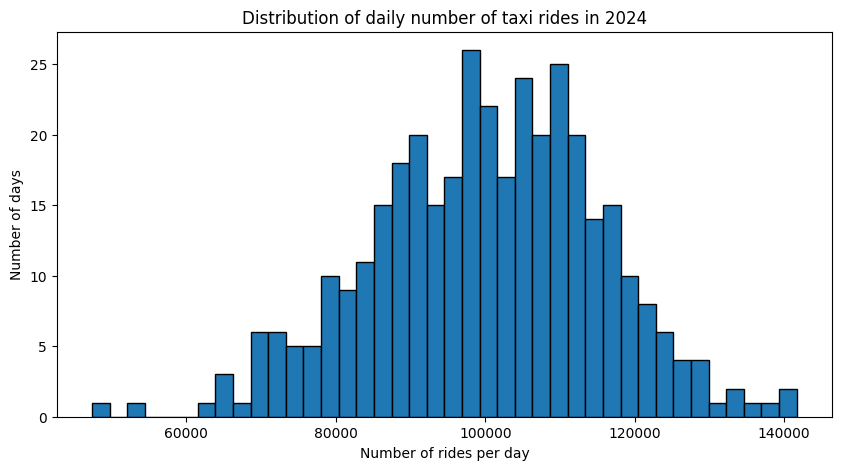

In [15]:
df_rides = dataset.select("date", "n_rides").to_pandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_rides["n_rides"], bins=40, edgecolor="black")
ax.set_title("Distribution of daily number of taxi rides in 2024")
ax.set_xlabel("Number of rides per day")
ax.set_ylabel("Number of days")
plt.show()

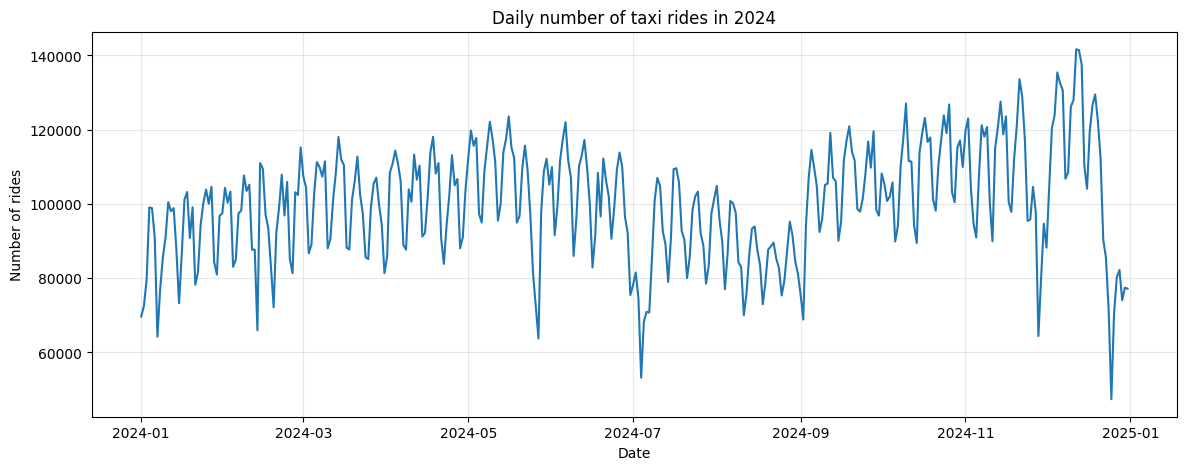

In [16]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_rides["date"], df_rides["n_rides"])
ax.set_title("Daily number of taxi rides in 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Number of rides")
ax.grid(alpha=0.3)
plt.show()